Proyecto 1 (10%)
Probabilidad y Estadística
Bioingeniería
20252


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats 
from statsmodels.sandbox.stats.runs import runstest_1samp # para la prueba Runs 
from statsmodels.formula.api import ols #modelo lineal del ANOVA
import statsmodels.api as sm #para generar la tabla anova
# from tabulate import tabulate # para tabular los dataframe
from statsmodels.stats.multicomp import pairwise_tukeyhsd# pruba de comparaciones multiples 
from scipy.stats import norm
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import QuantileTransformer



df = pd.read_csv("heart_attack_prediction_dataset.csv")
print(df.columns)

Index(['Patient ID', 'Age', 'Sex', 'Cholesterol', 'Blood Pressure',
       'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity',
       'Alcohol Consumption', 'Exercise Hours Per Week', 'Diet',
       'Previous Heart Problems', 'Medication Use', 'Stress Level',
       'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides',
       'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Country',
       'Continent', 'Hemisphere', 'Heart Attack Risk'],
      dtype='object')


o Determine la presencia de datos atípicos usando un diagrama de cajas y bigotes.

o Calcule los valores de media y mediana de cada variable.

o En el caso de haber datos ausentes, elimine estas filas, o reemplácelos por la media o la mediana.

o Describa el tipo de distribución que siguen las variables.

o Determine para cada variable si los datos presentan variabilidad alta, moderada o baja.

o Realice una descripción de todo lo anterior.

In [88]:
#Primero tomaremos los valores de forma numérica, como el Sex lo tenemos en valores categóricos
#Realizamos el cambio de estos

variables = ["Cholesterol", "Heart Rate", "Exercise Hours Per Week","BMI", "Sleep Hours Per Day","Smoking","Sex", "Heart Attack Risk"]
df_numerico = df[variables].copy()
df_numerico['Sex'] = df_numerico['Sex'].map({'Male': 1, 'Female': 0})
#Creamos un nuevo dataframe con solo las variables numericas
print(df_numerico.head())


   Cholesterol  Heart Rate  Exercise Hours Per Week        BMI  \
0          208          72                 4.168189  31.251233   
1          389          98                 1.813242  27.194973   
2          324          72                 2.078353  28.176571   
3          383          73                 9.828130  36.464704   
4          318          93                 5.804299  21.809144   

   Sleep Hours Per Day  Smoking  Sex  Heart Attack Risk  
0                    6        1    1                  0  
1                    7        1    1                  0  
2                    4        0    0                  0  
3                    4        1    1                  0  
4                    5        1    1                  0  


In [3]:
#Ahora miraremos si hay datos ausentes, utilizamos .info() para verificarlo
df_numerico.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Cholesterol              8763 non-null   int64  
 1   Heart Rate               8763 non-null   int64  
 2   Exercise Hours Per Week  8763 non-null   float64
 3   BMI                      8763 non-null   float64
 4   Sleep Hours Per Day      8763 non-null   int64  
 5   Smoking                  8763 non-null   int64  
 6   Sex                      8763 non-null   int64  
 7   Heart Attack Risk        8763 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 547.8 KB


Como los 8763 valores son non-null, quiere decir que no hay datos ausentes

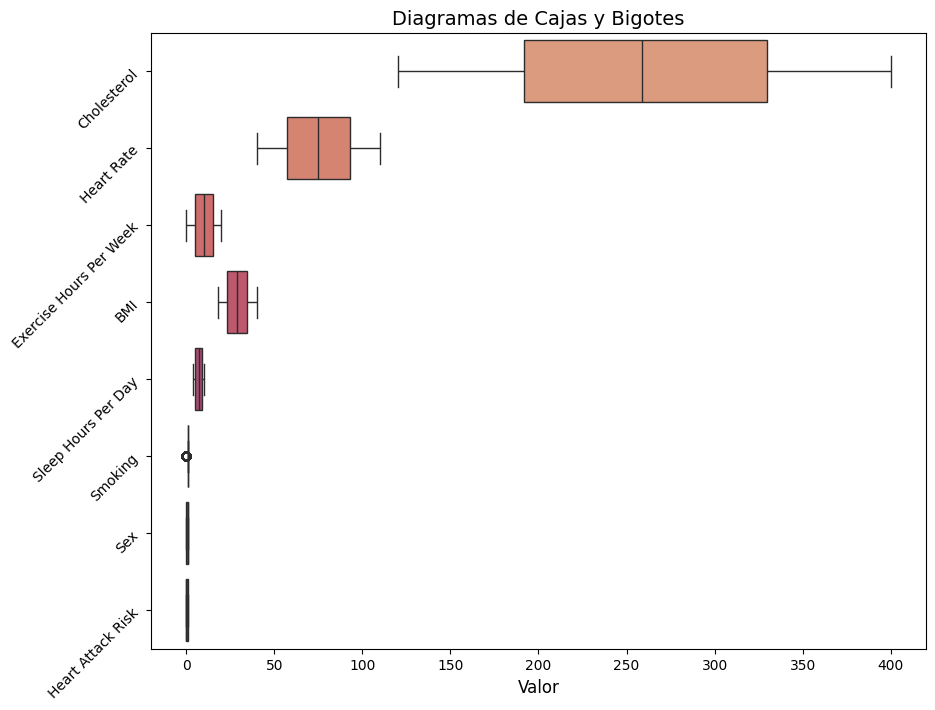

In [89]:
#Seguidamente haremos los diagramas de cajas y bigotes para cada variable numerica
plt.figure(figsize=(10, 8))
sns.boxplot(data=df_numerico, orient="h", palette="flare")
plt.title("Diagramas de Cajas y Bigotes", fontsize=14)
plt.xlabel("Valor", fontsize=12)
plt.yticks(rotation=45)
plt.show()

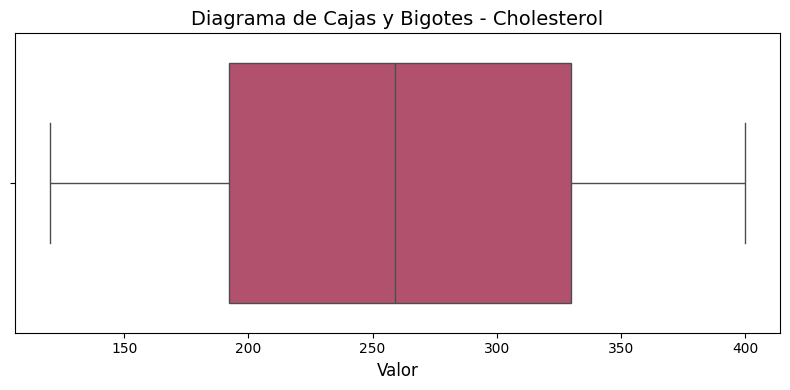

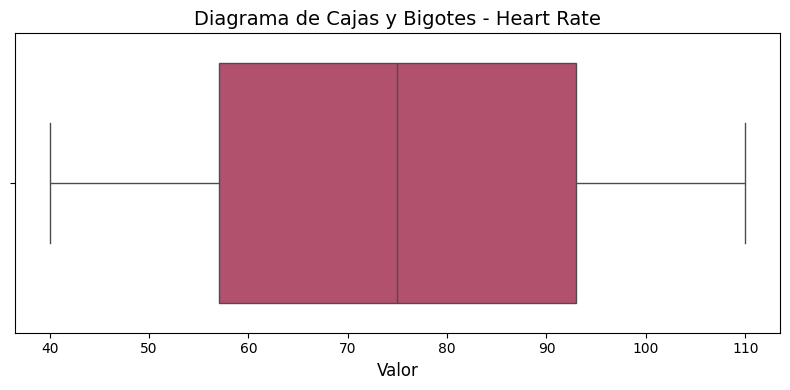

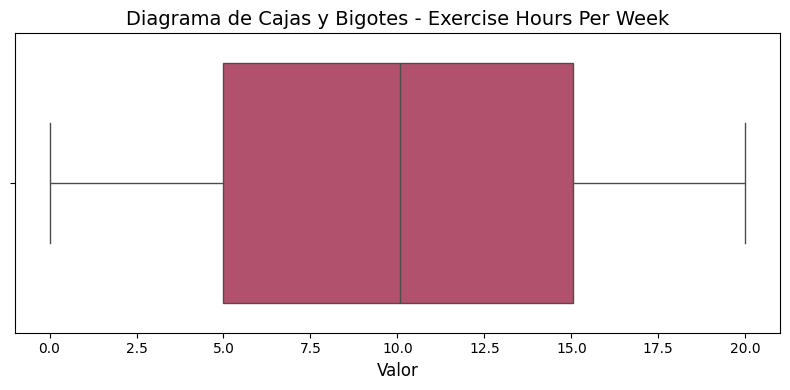

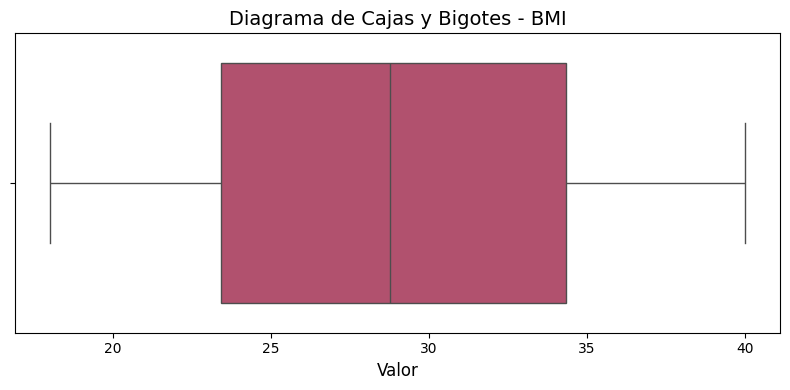

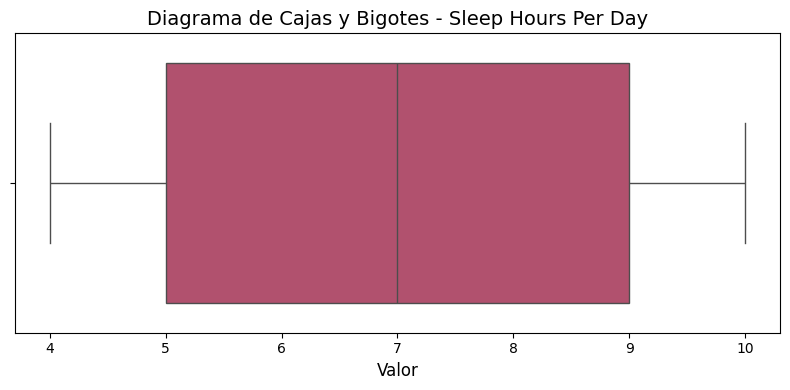

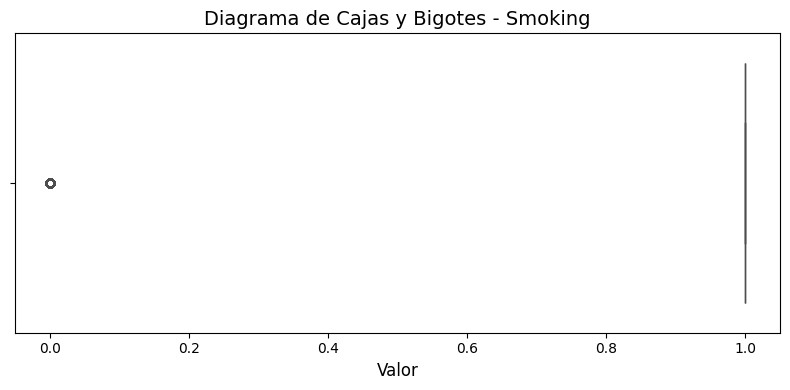

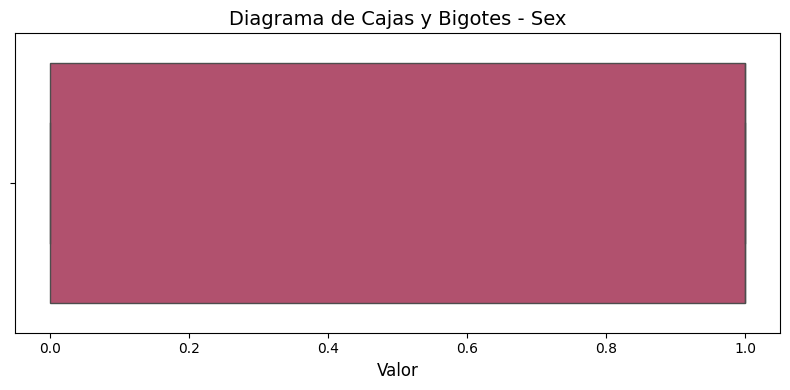

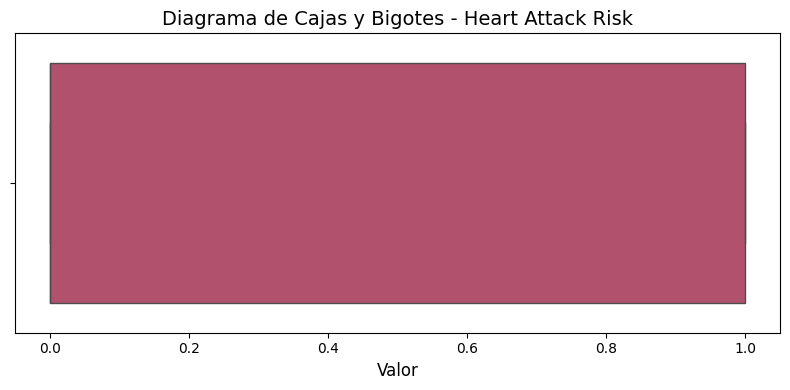

In [5]:
# Diagrama de cajas y bigotes para cada variable individualmente

for col in df_numerico.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_numerico[col], orient="h", palette="flare")
    plt.title(f"Diagrama de Cajas y Bigotes - {col}", fontsize=14)
    plt.xlabel("Valor", fontsize=12)
    plt.tight_layout()
    plt.show()

In [ ]:
df_numerico['Smoking'].unique()
df_numerico['Smoking'].value_counts()
#La variable Smoking muestra una distribución muy desbalanceada, con casi el 90 % de los participantes que fuman.
# Debido a esta falta de variabilidad, su diagrama de caja se aplana y no es representativo
#Aunque los diagramas de cajas y bigotes no son utiles para variables binominales, los incluimos para tener una visión completa de todas las variables numéricas.
# Sin embargo, es importante tener en cuenta que para variables binarias como Smoking, los diagramas de cajas y bigotes no son representativos debido a la falta de variabilidad en los datos.


Smoking
1    7859
0     904
Name: count, dtype: int64

In [7]:
#Ahora calculamos la media y la mediana
media = df_numerico.mean()
mediana = df_numerico.median()
print("Media:\n", media)
print("Mediana:\n", mediana)


Media:
 Cholesterol                259.877211
Heart Rate                  75.021682
Exercise Hours Per Week     10.014284
BMI                         28.891446
Sleep Hours Per Day          7.023508
Smoking                      0.896839
Sex                          0.697364
Heart Attack Risk            0.358211
dtype: float64
Mediana:
 Cholesterol                259.000000
Heart Rate                  75.000000
Exercise Hours Per Week     10.069559
BMI                         28.768999
Sleep Hours Per Day          7.000000
Smoking                      1.000000
Sex                          1.000000
Heart Attack Risk            0.000000
dtype: float64


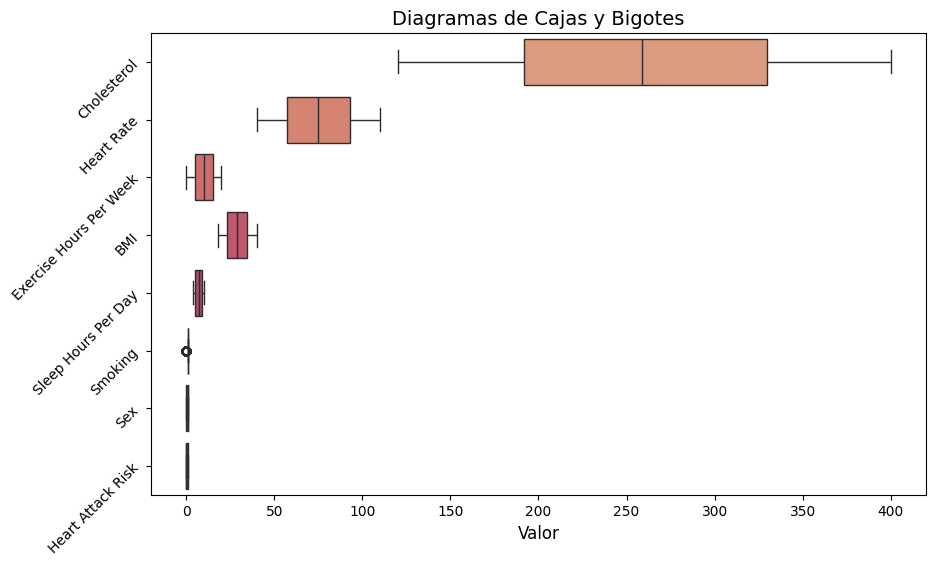

In [8]:
#----Si hubiesen valores nulos ó ausente podiamos hacer lo siguiente------
#Primero reemplazaremos los valores ausentes por la media de cada columna
df_numerico = df_numerico.fillna(media)
#Podemos verificar este cambio nuevamente en el diagrama de cajas y bigotes
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_numerico, orient="h", palette="flare")
plt.title("Diagramas de Cajas y Bigotes", fontsize=14)
plt.xlabel("Valor", fontsize=12)
plt.yticks(rotation=45)
plt.show()



In [9]:
#Ahora verificamos los datos atípicos para cada variable individualmente
# CHOLESTEROL
Q1 = df['Cholesterol'].quantile(0.25)
Q3 = df['Cholesterol'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['Cholesterol'] < lower_lim) | (df['Cholesterol'] > upper_lim)]

print("Datos atípicos encontrados en 'Cholesterol':")
print(outliers['Cholesterol'])
print("\n")

# HEART RATE
Q1 = df['Heart Rate'].quantile(0.25)
Q3 = df['Heart Rate'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['Heart Rate'] < lower_lim) | (df['Heart Rate'] > upper_lim)]

print("Datos atípicos encontrados en 'Heart Rate':")
print(outliers['Heart Rate'])
print("\n")

# EXERCISE HOURS PER WEEK
Q1 = df['Exercise Hours Per Week'].quantile(0.25)
Q3 = df['Exercise Hours Per Week'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['Exercise Hours Per Week'] < lower_lim) | (df['Exercise Hours Per Week'] > upper_lim)]

print("Datos atípicos encontrados en 'Exercise Hours Per Week':")
print(outliers['Exercise Hours Per Week'])
print("\n")

# BMI
Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['BMI'] < lower_lim) | (df['BMI'] > upper_lim)]

print("Datos atípicos encontrados en 'BMI':")
print(outliers['BMI'])
print("\n")

# SLEEP HOURS PER DAY
Q1 = df['Sleep Hours Per Day'].quantile(0.25)
Q3 = df['Sleep Hours Per Day'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['Sleep Hours Per Day'] < lower_lim) | (df['Sleep Hours Per Day'] > upper_lim)]

print("Datos atípicos encontrados en 'Sleep Hours Per Day':")
print(outliers['Sleep Hours Per Day'])
print("\n")

# HEART ATTACK RISK
Q1 = df['Heart Attack Risk'].quantile(0.25)
Q3 = df['Heart Attack Risk'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df[(df['Heart Attack Risk'] < lower_lim) | (df['Heart Attack Risk'] > upper_lim)]

print("Datos atípicos encontrados en 'Heart Attack Risk':")
print(outliers['Heart Attack Risk'])
print("\n")

# SEX
Q1 = df_numerico['Sex'].quantile(0.25)
Q3 = df_numerico['Sex'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df_numerico[(df_numerico['Sex'] < lower_lim) | (df_numerico['Sex'] > upper_lim)]

print("Datos atípicos encontrados en 'Sex':")
print(outliers['Sex'])
print("\n")


# SMOKING
Q1 = df_numerico['Smoking'].quantile(0.25)
Q3 = df_numerico['Smoking'].quantile(0.75)
IQR = Q3 - Q1

lower_lim = Q1 - 1.5 * IQR
upper_lim = Q3 + 1.5 * IQR

outliers = df_numerico[(df_numerico['Smoking'] < lower_lim) | (df_numerico['Smoking'] > upper_lim)]

print("Datos atípicos encontrados en 'Smoking':")
print(outliers['Smoking'])
print("\n")


Datos atípicos encontrados en 'Cholesterol':
Series([], Name: Cholesterol, dtype: int64)


Datos atípicos encontrados en 'Heart Rate':
Series([], Name: Heart Rate, dtype: int64)


Datos atípicos encontrados en 'Exercise Hours Per Week':
Series([], Name: Exercise Hours Per Week, dtype: float64)


Datos atípicos encontrados en 'BMI':
Series([], Name: BMI, dtype: float64)


Datos atípicos encontrados en 'Sleep Hours Per Day':
Series([], Name: Sleep Hours Per Day, dtype: int64)


Datos atípicos encontrados en 'Heart Attack Risk':
Series([], Name: Heart Attack Risk, dtype: int64)


Datos atípicos encontrados en 'Sex':
Series([], Name: Sex, dtype: int64)


Datos atípicos encontrados en 'Smoking':
2       0
30      0
36      0
37      0
40      0
       ..
8730    0
8734    0
8750    0
8759    0
8762    0
Name: Smoking, Length: 904, dtype: int64




Al aplicar el método del rango intercuartílico (IQR) para cada variable numérica (Cholesterol, Heart Rate, Exercise Hours Per Week, BMI, Sleep Hours Per Day,Sex ,Smoking y  Heart Attack Risk), no se identificaron valores que superaran los límites superior o inferior.
Por tanto, no se evidencian datos atípicos en estas variables según este criterio.

Ahora miraremos la distribución de las variables, para esto realizaremos el uso del histograma

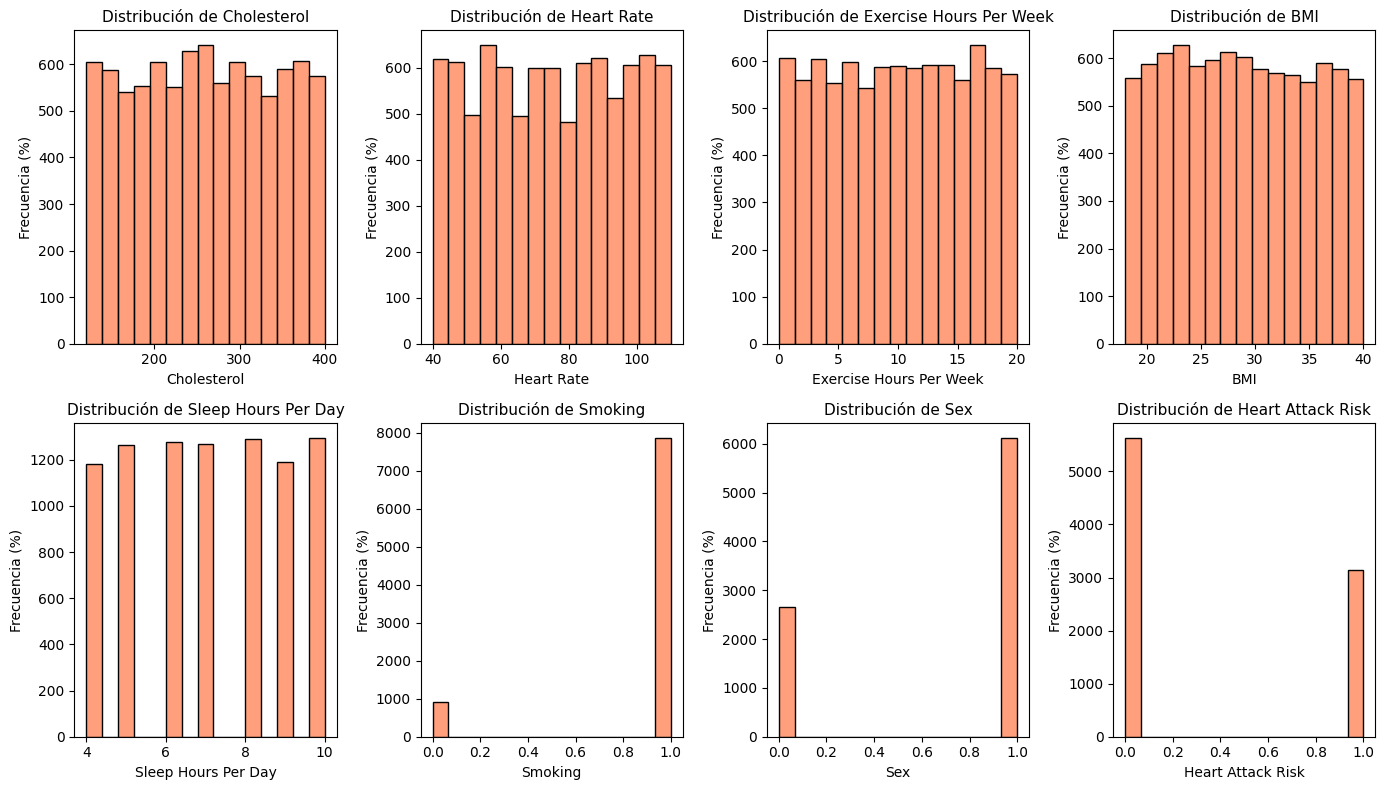

In [49]:
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(df_numerico.columns):
    sns.histplot(df_numerico[col], bins=15, kde=False, color='coral', ax=axes[i])
    axes[i].set_title(f"Distribución de {col}", fontsize=11)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel("Frecuencia (%)", fontsize=10)

plt.tight_layout()
plt.show()

Al analizar los histogramas de las variables numéricas (Cholesterol, Heart Rate, Exercise Hours Per Week, BMI, Sleep Hours Per Day y Heart Attack Risk), se observa que las distribuciones no siguen una forma normal.

En la mayoría de los casos (Cholesterol, Heart Rate, Exercise Hours Per Week, BMI, Sleep Hours Per Day), los datos presentan una distribución relativamente uniforme, donde las frecuencias se mantienen similares a lo largo del rango de valores sin concentrarse en un punto central.

En el caso de Heart Attack Risk,Sex y Smoking la variable es de tipo binaria (valores cercanos a 0 y 1), mostrando dos picos bien definidos, lo que indica una distribución bimodal.

En general, las variables muestran una dispersión moderada, sin sesgos marcados a la derecha o izquierda, y sin concentraciones que indiquen una tendencia normal o exponencial.

In [11]:
#Finalmente vamos a ver la variabilidad de las variables, para esto usaremos la desdiación estandar 
#MAD ya que es menos sensible a los valores atípicos que la desviación estándar tradicional
#Tomamos el rango CV < 10% como baja variabilidad porque es el límite comúnmente 
#aceptado en análisis estadísticos para indicar que los valores son homogéneos respecto a su media o mediana.

for i, col in enumerate(df_numerico.columns):
    mediana = np.median(df_numerico[col])
    desviaciones = abs(df_numerico[col] - mediana)
    MAD = np.median(desviaciones)
    CVM = (MAD / mediana) * 100

    # Variabilidad
    if CVM < 10:
        nivel = "Baja"
    elif CVM <= 20:
        nivel = "Moderada"
    else:
        nivel = "Alta"

    # Mostrar resultados
    print(f"{i+1}. Variable: {col}")
    print(f"   Mediana: {mediana:.2f}")
    print(f"   MAD: {MAD:.2f}")
    print(f"   CVM: {CVM:.2f}%")
    print(f"   Nivel de variabilidad: {nivel}\n")


1. Variable: Cholesterol
   Mediana: 259.00
   MAD: 69.00
   CVM: 26.64%
   Nivel de variabilidad: Alta

2. Variable: Heart Rate
   Mediana: 75.00
   MAD: 18.00
   CVM: 24.00%
   Nivel de variabilidad: Alta

3. Variable: Exercise Hours Per Week
   Mediana: 10.07
   MAD: 5.03
   CVM: 49.94%
   Nivel de variabilidad: Alta

4. Variable: BMI
   Mediana: 28.77
   MAD: 5.45
   CVM: 18.93%
   Nivel de variabilidad: Moderada

5. Variable: Sleep Hours Per Day
   Mediana: 7.00
   MAD: 2.00
   CVM: 28.57%
   Nivel de variabilidad: Alta

6. Variable: Smoking
   Mediana: 1.00
   MAD: 0.00
   CVM: 0.00%
   Nivel de variabilidad: Baja

7. Variable: Sex
   Mediana: 1.00
   MAD: 0.00
   CVM: 0.00%
   Nivel de variabilidad: Baja

8. Variable: Heart Attack Risk
   Mediana: 0.00
   MAD: 0.00
   CVM: nan%
   Nivel de variabilidad: Alta



Tomando en cuenta los histogramas y el CV podemos observar que 
Cholesterol:
El histograma es relativamente plano, lo que indica que los valores están repartidos entre los distintos niveles. Su CVM del 26.6% confirma una alta variabilidad, es decir, las personas presentan diferencias marcadas en los niveles de colesterol.

Heart Rate:
La distribución es amplia, con valores en todo el rango (40–110). El CVM del 24% refuerza esta alta variabilidad, mostrando diferencias notables en la frecuencia cardíaca de los sujetos.

Exercise Hours Per Week:
Muestra una dispersión casi total entre 0 y 20 horas, con CVM 49.9%, lo que representa la variabilidad más alta, coherente con que cada individuo tiene hábitos de ejercicio muy distintos.

BMI:
Aunque la distribución es más concentrada entre 20 y 35, sigue siendo bastante extendida. El CVM 18.9% indica una variabilidad moderada, es decir, los valores de índice de masa corporal son más homogéneos.

Sleep Hours Per Day:
Presenta barras agrupadas en valores discretos (4–10 horas), con poca variación entre categorías. Esto sugiere una baja o nula variabilidad real, aunque el cálculo del CVM no fue posible por falta de dispersión.

Heart Attack Risk,Smoking & Sex:
Se observan dos grupos extremos (en 0 y 1), indicando una variable binaria (riesgo bajo o alto). No es adecuada para medir variabilidad continua, pero gráficamente se aprecia una distribución dicotómica, aún así decidimos poner estas variables en el análisis de normalidad para tener un análisis más completo de todas las variables.




Descripción de lo realizado:
En este análisis se evaluaron las variables Cholesterol, Heart Rate, Exercise Hours Per Week, BMI, Sleep Hours Per Day, Sex, Smoking y Heart Attack Risk con el objetivo de identificar la presencia de datos atípicos, el nivel de variabilidad y el tipo de distribución que siguen los datos.

1. Datos atípicos y valores ausentes
A partir de los diagramas de cajas y bigotes, no se detectaron valores atípicos significativos en ninguna de las variables numéricas analizadas.
Además, mediante la función df.info() se comprobó que el conjunto de datos no contiene valores ausentes, por lo que no fue necesario aplicar reemplazos por media o mediana.

2. Medidas de tendencia central y dispersión (CVM y MAD)
Los resultados obtenidos fueron los siguientes:

Cholesterol: Mediana 259, MAD 69, CVM 26.64% → Alta variabilidad

Heart Rate: Mediana 75, MAD 18, CVM 24.00% → Alta variabilidad

Exercise Hours Per Week: Mediana 10.07, MAD 5.03, CVM 49.94% → Alta variabilidad

BMI: Mediana 28.77, MAD 5.45, CVM 18.93% → Variabilidad moderada

Sleep Hours Per Day: sin variación aparente → Baja variabilidad


El coeficiente de variación basado en la mediana (CVM) se interpretó de la siguiente manera:

CVM < 10% → Baja variabilidad

10% ≤ CVM ≤ 20% → Moderada variabilidad

CVM > 20% → Alta variabilidad

3. Distribución de las variables
Los histogramas muestran que las distribuciones no son normales.
Las variables Cholesterol, Heart Rate, Exercise Hours Per Week y BMI presentan una distribución relativamente uniforme, sin sesgos marcados, lo cual indica que los valores están repartidos de forma similar en todo el rango.
Por otro lado, Sleep Hours Per Day muestra una concentración estable en los mismos intervalos, y Heart Attack Risk, Sex y Smoking tiene una forma claramente bimodal, concentrada en los valores 0 y 1, lo que corresponde a su naturaleza categórica

4. En general
En conjunto, los resultados indican que las variables analizadas presentan una dispersión entre moderada y alta, lo que refleja diferencias notables entre individuos del conjunto de datos.
Las distribuciones observadas confirman que los datos no siguen una forma normal, sino más bien uniforme o categórica, dependiendo de la variable.
La ausencia de valores atípicos y nulos sugiere que el conjunto de datos es limpio y adecuado para análisis posteriores, como correlaciones o modelos predictivos.

---------------------------Punto 2------------------------------------------

Determine para las variables numéricas, si existe diferencia estadística entre, hombres y mujeres, entre fumadores y no fumadores, y entre personas con riesgo de infarto y sin riesgo.

In [12]:
def test_normalityKS(data, variable): # Pruaba de Normalidad Kolmogorov-Smirnof 
    """
    data: arreglo de datos a evaluar la normalidad
    variable: string con el nombre de la variable 
    """  
    print(f"\n Análisis de normalidad por Kolmogorov-Smirnov para '{variable}'")

    # Kolmogorov-Smirnov (KS) test
    ks_stat, ks_p = stats.kstest(data, 'norm', args=(np.mean(data), np.std(data)))
    print(f" Estadístico = {ks_stat:.4f}, p-valor = {ks_p:.4f}")
    

Primero haremos una verificación de la normalidad de nuestras variables numéricas
Como son 8736 datos, haremos la prueba de Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, donde plantearemos las siguientes hipótesis

Ho: Los datos provienen de una distribución normal

H1: Los datos no provienen de una distribución normal


In [13]:
#Primero erificamos si existe esta diferencia estadistica con la variable numerica Cholesterol
#Para esto separamos los datos por grupo

# Separar colesterol por sexo
# df_numerico['Sex'] = df_numerico['Sex'].map({'Male': 1, 'Female': 0})

chol_male = df[df_numerico['Sex'] == 1]['Cholesterol'].dropna()
chol_female = df[df_numerico['Sex'] == 0]['Cholesterol'].dropna()

# Prueba de normalidad en ambos grupos
test_normalityKS(chol_female, "Cholesterol - Mujeres")
test_normalityKS(chol_male, "Cholesterol - Hombres")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Mujeres'
 Estadístico = 0.0628, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Hombres'
 Estadístico = 0.0579, p-valor = 0.0000


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales ni en hombres ni en mujeres.
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [14]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution='normal', random_state=0)

chol_male_qt = qt.fit_transform(chol_male.values.reshape(-1, 1)).flatten()
chol_female_qt = qt.fit_transform(chol_female.values.reshape(-1, 1)).flatten()

# Verificar nuevamente normalidad
test_normalityKS(chol_male_qt, "Cholesterol (QT) - Hombres")
test_normalityKS(chol_female_qt, "Cholesterol (QT) - Mujeres")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - Hombres'
 Estadístico = 0.0169, p-valor = 0.0596

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - Mujeres'
 Estadístico = 0.0218, p-valor = 0.1572


Dado que ambos p-valores > 0.05, no se rechaza la hipótesis nula de normalidad
Por tanto, las distribuciones transformadas pueden considerarse normales
El QuantileTransformer toma los datos originales (que pueden ser asimétricos o con colas largas) y los transforma de tal forma que su distribución final sea aproximadamente normal

Por ser el primer caso, veremos su uso en un histograma para observar la transformación, luego continuaremos con las pruebas correspondientes


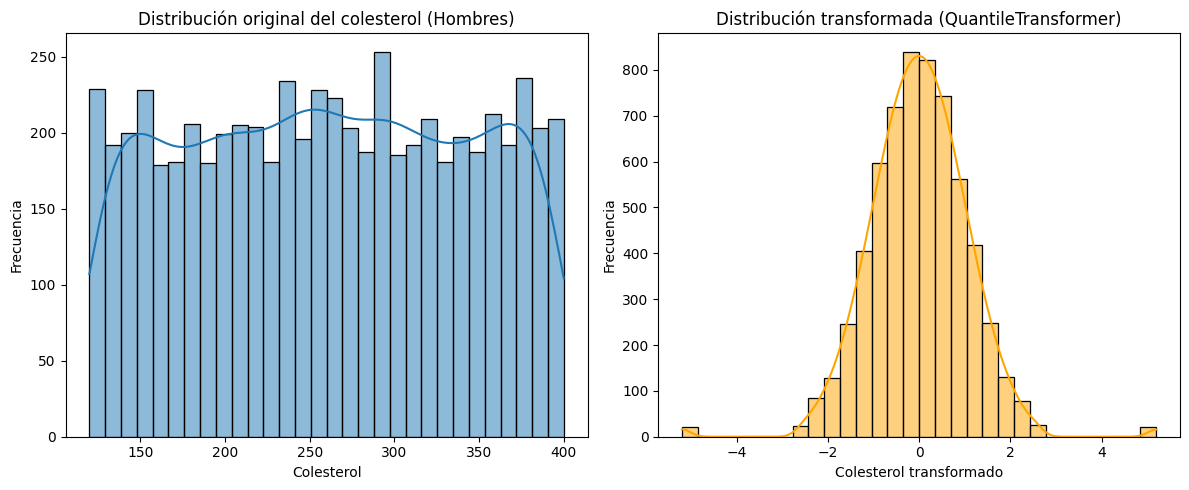

In [15]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(chol_male, kde=True, bins=30)
plt.title("Distribución original del colesterol (Hombres)")
plt.xlabel("Colesterol")
plt.ylabel("Frecuencia")

plt.subplot(1,2,2)
sns.histplot(chol_male_qt, kde=True, bins=30, color="orange")
plt.title("Distribución transformada (QuantileTransformer)")
plt.xlabel("Colesterol transformado")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

--------Realizar histogramas para verificar normalidad-----------

-----------#####################################---------------

Continuando con nuestras pruebas, realizaremos la validación de Homocedasticidad
Supuestos de Homocedasticidad, prueba de Levene:

Ho: Los dos grupos de datos presentan varianza constante 

H1: Los dos grupos de datos no presentan varianza constante.

In [16]:

def test_homogeneityL(var1, var2, name1, name2): # Prueba de levene
    """
    var1 y var2: variables a las que se corroborará homocedasticidad 
    name1 y name2: strings con el nnombre de las variables
    """
    print(f"\n Análisis de homocedasticidad entre '{name1}' y '{name2}'")

    # Prueba de Levene (no asume normalidad)
    levene_stat, levene_p = stats.levene(var1, var2)
    print(f"Levene test: Estadístico = {levene_stat:.4f}, p-valor = {levene_p:.4f}")

test_homogeneityL(chol_male_qt, chol_female_qt, "Hombres", "Mujeres")



 Análisis de homocedasticidad entre 'Hombres' y 'Mujeres'
Levene test: Estadístico = 0.0860, p-valor = 0.7693


Como el valor P es mayor a 0.05, no echazamos H0, por lo tanto podemos confirmar que las varianzas son estadisticamente iguales, se cumple nuestro supuesto de homogeneidad, ahora continuamos con las pruebas parametricas


Supuestos de prueba T:

Ho: Las medias de las muestras son iguales 

H1: Las medias de las muestras son diferentes

In [17]:
from scipy.stats import ttest_ind #prueba t para dos muestras independientes 
def t_test_two_sample(datos1,datos2):#prubea T para dos muestras
    """
    datos1: datos de la primera muestra 
    datos2: datos de la segunda muestra
    """
    
    t_stat, p_value = ttest_ind(datos1, datos2)
    print(f"Prueba t para dos muestras, valor p: {p_value:.4f}")

t_test_two_sample(chol_male_qt, chol_female_qt)


Prueba t para dos muestras, valor p: 0.8914


Como el p-valor = 0.8914 > 0.05, no se rechaza H0
Lo cual indica que los niveles de colesterol promedio entre hombres y mujeres son estadísticamente similares.
No se observa una diferencia significativa entre los grupos.


Como ya tenemos nuestras pruebas definidad, haremos las pruebas correspondiente verificando las hipotesis

Primero Normalidad
Aplicaos Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal


In [18]:
#-----------------Smoking------------------
chol_smokers = df[df['Smoking'] == 1]['Cholesterol'].dropna()
chol_nonsmokers = df[df['Smoking'] == 0]['Cholesterol'].dropna()

test_normalityKS(chol_smokers, "Cholesterol - Fumadores")
test_normalityKS(chol_nonsmokers, "Cholesterol - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Fumadores'
 Estadístico = 0.0585, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - No Fumadores'
 Estadístico = 0.0666, p-valor = 0.0006


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales en fumadores y no.
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [19]:
chol_smokers_qt = qt.fit_transform(chol_smokers.values.reshape(-1, 1)).flatten()
chol_nonsmokers_qt = qt.fit_transform(chol_nonsmokers.values.reshape(-1, 1)).flatten()

test_normalityKS(chol_smokers_qt, "Cholesterol (QT) - Fumadores")
test_normalityKS(chol_nonsmokers_qt, "Cholesterol (QT) - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - Fumadores'
 Estadístico = 0.0181, p-valor = 0.0113

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - No Fumadores'
 Estadístico = 0.0205, p-valor = 0.8328
 Estadístico = 0.0181, p-valor = 0.0113

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - No Fumadores'
 Estadístico = 0.0205, p-valor = 0.8328


El valor P para fumadores despues de la transformación es menor a nuestro alfa, por lo cuál no se cumple la normalidad, así que procedemos en aplicar una prueba no paramétrica, usaremos el análogo a la prueba T, la cual es U Mann Withney sobre los valores originales donde tendremos los siguientes supuestos

H0: No hay diferencia significativa en los niveles de colesterol entre fumadores y no fumadores.

H1: Sí hay diferencia significativa entre los grupos.

In [20]:
from scipy.stats import mannwhitneyu

def U_Mann_W (datos1,datos2):# pruba U Mann Withney
    """
    datos1: primer set de datos a comparar
    datos2: segundo set de datos a comparar
    """
    # Prueba de Mann-Whitney
    stat, p_value = mannwhitneyu(datos1, datos2, alternative='two-sided')
    # Mostrar resultados
    print(f"Estadístico U: {stat}")
    print(f"P-valor: {p_value:.4f}")

U_Mann_W(chol_smokers, chol_nonsmokers)

    


Estadístico U: 3663842.0
P-valor: 0.1214

P-valor: 0.1214


Como el valor 0.1214>0.05 no se rechaza H0, por lo tanto los fumadores y los no fumadores parecen tener niveles de colesterol similares según los datos.

Continuamos con Heartk Attack Risk
Usaremos Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 

Ho: Los datos provienen de una distribución normal

H1: Los datos no provienen de una distribución normal


In [21]:
#---------------------Heart Attack Risk-----------------------
chol_attack = df[df['Heart Attack Risk'] == 1]['Cholesterol'].dropna()
chol_noattack = df[df['Heart Attack Risk'] == 0]['Cholesterol'].dropna()

test_normalityKS(chol_attack, "Cholesterol - Con Riesgo de Infarto")
test_normalityKS(chol_noattack, "Cholesterol - Sin Riesgo de Infarto")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Con Riesgo de Infarto'
 Estadístico = 0.0633, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Sin Riesgo de Infarto'
 Estadístico = 0.0575, p-valor = 0.0000
 Estadístico = 0.0633, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol - Sin Riesgo de Infarto'
 Estadístico = 0.0575, p-valor = 0.0000


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [22]:
chol_attack_qt = qt.fit_transform(chol_attack.values.reshape(-1, 1)).flatten()
chol_noattack_qt = qt.fit_transform(chol_noattack.values.reshape(-1, 1)).flatten()


# Verificar normalidad post-transformación
test_normalityKS(chol_attack_qt, "Cholesterol (QT) - Con Riesgo de Infarto")
test_normalityKS(chol_noattack_qt, "Cholesterol (QT) - Sin Riesgo de Infarto")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - Con Riesgo de Infarto'
 Estadístico = 0.0177, p-valor = 0.2777

 Análisis de normalidad por Kolmogorov-Smirnov para 'Cholesterol (QT) - Sin Riesgo de Infarto'
 Estadístico = 0.0186, p-valor = 0.0410


En el grupo sin riesgo, el p = 0.041 < 0.05 indica que se rechaza la normalidad luego de la transformación, por lo cuál procederemos a realizar la prueba U Mann Whitney con las variables originales donde los supuestos son los siguientes

H0: No hay diferencia significativa en los niveles

H1: Sí hay diferencia significativa entre los grupos.





In [23]:
U_Mann_W(chol_attack_qt, chol_noattack_qt)


Estadístico U: 8825338.5
P-valor: 0.9893


El p-valor = 0.9893 > 0.05, lo que significa que no se rechaza la hipótesis nula (H0}, de lo cual podemos afirmar que no se encontraron diferencias estadísticamente significativas en los niveles de colesterol entre los individuos con riesgo de infarto y aquellos sin riesgo.
Esto sugiere que, en este conjunto de datos, el colesterol no parece ser un factor diferenciador principal entre ambos grupos.

Como conclusión del Colesterol  el análisis de la variable Cholesterol, se evaluó si existían diferencias estadísticamente significativas en los niveles de colesterol según el sexo, el hábito de fumar y el riesgo de infarto. Los resultados mostraron que no hubo diferencias significativas entre hombres y mujeres (p = 0.8914), lo que sugiere que ambos grupos presentan niveles de colesterol similares. De igual manera, al comparar fumadores y no fumadores (p = 0.1214), no se evidenció una variación significativa, indicando que el hábito de fumar no parece afectar los valores de colesterol en esta muestra. Finalmente, al analizar a las personas con y sin riesgo de infarto, y tras aplicar la transformación de Quantile Transformer para cumplir los supuestos de normalidad, la prueba no paramétrica de Mann–Whitney (p = 0.9893) mostró que tampoco existen diferencias relevantes entre ambos grupos. En conjunto, estos resultados sugieren que, dentro de este conjunto de datos, los niveles de colesterol se mantienen estadísticamente similares entre los distintos grupos analizados, por lo que el colesterol no se comporta como un factor diferenciador ni se asocia significativamente con el riesgo de infarto.

In [24]:
#-------------------Heart Rate----------------------

Continuaremos con nuestra variable numérica de Hear Rate
Comenzaremos verificando nuestra normalidad tomando
Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal


In [25]:
hr_male = df[df_numerico['Sex'] == 1]['Heart Rate'].dropna()
hr_female = df[df_numerico['Sex'] == 0]['Heart Rate'].dropna()

# Prueba de normalidad en ambos grupos
test_normalityKS(hr_female, "Heart Rate - Mujeres")
test_normalityKS(hr_male, "Heart Rate - Hombres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - Mujeres'
 Estadístico = 0.0724, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - Hombres'
 Estadístico = 0.0671, p-valor = 0.0000 Estadístico = 0.0671, p-valor = 0.0000



Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales 
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [26]:
hr_male_qt = qt.fit_transform(hr_male.values.reshape(-1, 1)).flatten()
hr_female_qt = qt.fit_transform(hr_female.values.reshape(-1, 1)).flatten()

test_normalityKS(hr_male_qt, "Heart Rate (QT) - Hombres")
test_normalityKS(hr_female_qt, "Heart Rate (QT) - Mujeres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - Hombres'
 Estadístico = 0.0618, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - Mujeres'
 Estadístico = 0.0610, p-valor = 0.0000


Como ambos p-valores son menores que 0.05, se rechaza la hipótesis nula de normalidad

Esto significa que la distribución de la variable Heart Rate (QT) no sigue una distribución normal en ninguno de los grupos

Por lo tanto continuaremos con la pruena no paramétrica U Mann Wwhitney

H0: No hay diferencia significativa en los niveles

H1: Sí hay diferencia significativa entre los grupos.



In [27]:
U_Mann_W(hr_male, hr_female)


Estadístico U: 7992273.5
P-valor: 0.3079


El valor p obtenido (0.3079) es mayor que 0.05, por lo tanto no se rechaza la hipótesis nula (H0)
Esto indica que no existe una diferencia estadísticamente significativa en las medianas de la frecuencia cardíaca (Heart Rate) entre hombres y mujeres

En otras palabras, con base en los datos disponibles, el ritmo cardíaco promedio de hombres y mujeres es similar desde un punto de vista estadístico

Ahora continuaremos con la variable de Smoking utilizando Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal


In [28]:
#-----------------Smoking------------------
hr_smokers = df[df['Smoking'] == 1]['Heart Rate'].dropna()
hr_nonsmokers = df[df['Smoking'] == 0]['Heart Rate'].dropna()

test_normalityKS(hr_smokers, "Heart Rate - Fumadores")
test_normalityKS(hr_nonsmokers, "Heart Rate - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - Fumadores'
 Estadístico = 0.0668, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - No Fumadores'
 Estadístico = 0.0788, p-valor = 0.0000

 Estadístico = 0.0668, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - No Fumadores'
 Estadístico = 0.0788, p-valor = 0.0000


COmo los valores P son meores a 0.05, descartamos H0 el cuál afirma que la distribución es normal, continuamos a realizar la transforación para verificar su normalidad nuevamente



In [29]:
hr_smokers_qt = qt.fit_transform(hr_smokers.values.reshape(-1, 1)).flatten()
hr_nonsmokers_qt = qt.fit_transform(hr_nonsmokers.values.reshape(-1, 1)).flatten()

# Prueba de normalidad después de la transformación
test_normalityKS(hr_smokers_qt, "Heart Rate (QT) - Fumadores")
test_normalityKS(hr_nonsmokers_qt, "Heart Rate (QT) - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - Fumadores'
 Estadístico = 0.0607, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - No Fumadores'
 Estadístico = 0.0671, p-valor = 0.0006


Los p-valores siguen siendo < 0.05

Por lo tanto, se rechaza la hipótesis nula de que los datos provienen de una distribución normal, entonces realizaremos una prueba no paramétrica U Mann donde los supuestos son

H0: No hay diferencia significativa en los niveles

H1: Sí hay diferencia significativa entre los grupos.


In [30]:
U_Mann_W(hr_smokers, hr_nonsmokers)


Estadístico U: 3469245.0
P-valor: 0.2490


Como el valor p-valor de 0.2490, el cual es mayor al nivel de significancia convencional de 0.05

Por lo tanto, no se rechaza la hipótesis nula, concluyendo que no existe una diferencia estadísticamente significativa en la frecuencia cardíaca entre fumadores y no fumadores en esta muestra.


Finalmente haremos nuestra comparación con los valores de Heart Attack Risk, primero aplicaremos normalidad para verificarla, teniendo nuestros supuestos de la prueba Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 

Ho: Los datos provienen de una distribución normal

H1: Los datos no provienen de una distribución normal


In [31]:
#-------------------------Heart Attack Risk-----------------------
hr_risk = df[df['Heart Attack Risk'] == 1]['Heart Rate'].dropna()
hr_no_risk = df[df['Heart Attack Risk'] == 0]['Heart Rate'].dropna()

test_normalityKS(hr_risk, "Heart Rate - Con Riesgo de Infarto")
test_normalityKS(hr_no_risk, "Heart Rate - Sin Riesgo de Infarto")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - Con Riesgo de Infarto'
 Estadístico = 0.0734, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate - Sin Riesgo de Infarto'
 Estadístico = 0.0701, p-valor = 0.0000


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales 
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [32]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)

hr_risk_qt = QT.fit_transform(hr_risk.values.reshape(-1,1)).flatten()
hr_no_risk_qt = QT.fit_transform(hr_no_risk.values.reshape(-1,1)).flatten()

test_normalityKS(hr_risk_qt, "Heart Rate (QT) - Con Riesgo de Infarto")
test_normalityKS(hr_no_risk_qt, "Heart Rate (QT) - Sin Riesgo de Infarto")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - Con Riesgo de Infarto'
 Estadístico = 0.0619, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Heart Rate (QT) - Sin Riesgo de Infarto'
 Estadístico = 0.0609, p-valor = 0.0000


Ya que ambos p-valores son menores que 0.05.

Por tanto, no se cumple el supuesto de normalidad y debemos aplicar una prueba la U de Mann Whitney donde


H0: No hay diferencia significativa en los niveles

H1: Sí hay diferencia significativa entre los grupos.


In [33]:
U_Mann_W(hr_risk, hr_no_risk)


Estadístico U: 8780068.5
P-valor: 0.6802


Como p-valor = 0.6802, el cual es mayor al nivel de significancia 0.05

Por lo tanto, no se rechaza la hipótesis nula (H0), concluyendo que no existe evidencia estadísticamente significativa de diferencias en la frecuencia cardíaca entre las personas con y sin riesgo de infarto en esta muestra

En el análisis de la variable Heart Rate, se evaluaron posibles diferencias entre los grupos de hombres y mujeres, fumadores y no fumadores, y entre personas con y sin riesgo de infarto

En todos los casos, las pruebas de normalidad indicaron que la distribución de los datos no seguía una distribución normal, por lo cual se aplicaron las pruebas no paramétricas correspondientes (U de Mann Whitney)

Los resultados obtenidos mostraron valores p mayores a 0.05 en todas las comparaciones, lo que indica que no existen diferencias estadísticamente significativas en la frecuencia cardíaca entre los grupos evaluados

En conclusión, la frecuencia cardíaca promedio no parece verse influenciada por el sexo, el hábito de fumar o el riesgo de infarto dentro de esta muestra de datos

In [34]:
#----------Hour Exercise Per Week----------------

Ahora comenzaremos con Hour Exercise Per Week, primero realizaremos la prueba de normalidad de Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 

Ho: Los datos provienen de una distribución normal

H1: Los datos no provienen de una distribución normal


In [35]:
ex_male = df[df_numerico['Sex'] == 1]['Exercise Hours Per Week'].dropna()
ex_female = df[df_numerico['Sex'] == 0]['Exercise Hours Per Week'].dropna()
test_normalityKS(ex_male, "Exercise Hours Per Week - Hombres")
test_normalityKS(ex_female, "Exercise Hours Per Week - Mujeres")




 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - Hombres'
 Estadístico = 0.0600, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - Mujeres'
 Estadístico = 0.0651, p-valor = 0.0000
 Estadístico = 0.0651, p-valor = 0.0000


los p-valores < 0.05, la variable no es normal y pasamos al siguiente paso el cuál es aplicar la transformación

In [36]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)

ex_male_qt = QT.fit_transform(ex_male.values.reshape(-1,1)).flatten()
ex_female_qt = QT.fit_transform(ex_female.values.reshape(-1,1)).flatten()

test_normalityKS(ex_male_qt, "Exercise Hours Per Week (QT) - Hombres")
test_normalityKS(ex_female_qt, "Exercise Hours Per Week (QT) - Mujeres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - Hombres'
 Estadístico = 0.0014, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - Mujeres'
 Estadístico = 0.0025, p-valor = 1.0000


Como nuestro valor P nos dios un p valor de 1.0000, podemos afirmar que nuestros datos son normales, ahora haremos la prueba de homocedasticidad

H0: Las varianzas son iguales.

H1: Las varianzas son diferentes.


In [37]:
test_homogeneityL(ex_male_qt, ex_female_qt, "Hombres", "Mujeres")



 Análisis de homocedasticidad entre 'Hombres' y 'Mujeres'
Levene test: Estadístico = 0.0059, p-valor = 0.9390


El p-valor es mucho mayor a 0.05, por lo tanto no se rechaza la hipótesis nula de Levene

Esto significa que las varianzas entre hombres y mujeres son homogéneas, y se cumplen todos los supuestos para la t donde

Ho: Las medias de las muestras son iguales 

H1: Las medias de las muestras son diferentes


In [38]:
t_test_two_sample(ex_male_qt, ex_female_qt)


Prueba t para dos muestras, valor p: 0.9890


El resultado arrojó un p-valor de 0.9890, mayor al nivel de significancia α = 0.05

Por lo tanto, no se rechaza la hipótesis nula, concluyendo que no existen diferencias estadísticamente significativas en la cantidad de horas de ejercicio semanal entre hombres y mujeres en esta muestra

Ahora continuaremos con smoking, haciendo uso de la prueba de normalidad Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal

In [39]:
ex_smokers = df[df['Smoking'] == 1]['Exercise Hours Per Week'].dropna()
ex_nonsmokers = df[df['Smoking'] == 0]['Exercise Hours Per Week'].dropna()

test_normalityKS(ex_smokers, "Exercise Hours Per Week - Fumadores")
test_normalityKS(ex_nonsmokers, "Exercise Hours Per Week - No Fumadores")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - Fumadores'
 Estadístico = 0.0603, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - No Fumadores'


 Estadístico = 0.0659, p-valor = 0.0007


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales 
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [40]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)
ex_smokers_qt = QT.fit_transform(ex_smokers.values.reshape(-1,1)).flatten()
ex_nonsmokers_qt = QT.fit_transform(ex_nonsmokers.values.reshape(-1,1)).flatten()

test_normalityKS(ex_smokers_qt, "Exercise Hours Per Week (QT) - Fumadores")
test_normalityKS(ex_nonsmokers_qt, "Exercise Hours Per Week (QT) - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - Fumadores'
 Estadístico = 0.0011, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - No Fumadores'
 Estadístico = 0.0055, p-valor = 1.0000


Como nuestro valor P nos dios un p valor de 1.0000, podemos afirmar que nuestros datos son normales, ahora haremos la prueba de homocedasticidad

H0: Las varianzas son iguales.

H1: Las varianzas son diferentes.

In [41]:
test_homogeneityL(ex_smokers_qt, ex_nonsmokers_qt, "Fumadores", "No Fumadores")




 Análisis de homocedasticidad entre 'Fumadores' y 'No Fumadores'
Levene test: Estadístico = 0.0753, p-valor = 0.7838


Como el valor P es mayor a 0.05, no echazamos H0, por lo tanto podemos confirmar que las varianzas son estadisticamente iguales, se cumple nuestro supuesto de homogeneidad, ahora continuamos con las pruebas parametricas

In [42]:
t_test_two_sample(ex_smokers_qt, ex_nonsmokers_qt)


Prueba t para dos muestras, valor p: 0.9997


El resultado arrojó un p-valor de 0.9997, mayor al nivel de significancia α = 0.05

Por lo tanto, no se rechaza la hipótesis nula, concluyendo que no existen diferencias estadísticamente significativas en la cantidad de horas de ejercicio semanal entre fumadores y no fumadores en esta muestra.

Ahora continuaremos con Heart Attack Risk, haciendo uso de la prueba de normalidad Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal

In [43]:
ex_risk = df[df['Heart Attack Risk'] == 1]['Exercise Hours Per Week'].dropna()
ex_no_risk = df[df['Heart Attack Risk'] == 0]['Exercise Hours Per Week'].dropna()

test_normalityKS(ex_risk, "Exercise Hours Per Week - Con Riesgo de Infarto")
test_normalityKS(ex_no_risk, "Exercise Hours Per Week - Sin Riesgo de Infarto")




 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - Con Riesgo de Infarto'
 Estadístico = 0.0631, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week - Sin Riesgo de Infarto'
 Estadístico = 0.0604, p-valor = 0.0000


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales 
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [44]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)
ex_risk_qt = QT.fit_transform(ex_risk.values.reshape(-1,1)).flatten()
ex_no_risk_qt = QT.fit_transform(ex_no_risk.values.reshape(-1,1)).flatten()

test_normalityKS(ex_risk_qt, "Exercise Hours Per Week (QT) - Con Riesgo de Infarto")
test_normalityKS(ex_no_risk_qt, "Exercise Hours Per Week (QT) - Sin Riesgo de Infarto")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - Con Riesgo de Infarto'
 Estadístico = 0.0022, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Exercise Hours Per Week (QT) - Sin Riesgo de Infarto'
 Estadístico = 0.0013, p-valor = 1.0000


Dado que ambos p-valores > 0.05, no se rechaza la hipótesis nula de normalidad
Por tanto, las distribuciones transformadas pueden considerarse normales

Continuando con nuestras pruebas, realizaremos la validación de Homocedasticidad
Supuestos de Homocedasticidad, prueba de Levene:
Ho: Los dos grupos de datos presentan varianza constante 
H1: Los dos grupos de datos no presentan varianza constante.


In [45]:
test_homogeneityL(ex_risk_qt, ex_no_risk_qt, "Con Riesgo", "Sin Riesgo")



 Análisis de homocedasticidad entre 'Con Riesgo' y 'Sin Riesgo'
Levene test: Estadístico = 0.0049, p-valor = 0.9444


Como el valor P es mayor a 0.05, no echazamos H0, por lo tanto podemos confirmar que las varianzas son estadisticamente iguales, se cumple nuestro supuesto de homogeneidad, ahora continuamos con las pruebas parametricas

Supuestos de prueba T:

Ho: Las medias de las muestras son iguales 

H1: Las medias de las muestras son diferentes


In [46]:
t_test_two_sample(ex_risk_qt, ex_no_risk_qt)


Prueba t para dos muestras, valor p: 0.9960


El resultado arrojó un p-valor de 0.9960, mayor al nivel de significancia 0.05

Por lo tanto, no se rechaza la hipótesis nula, concluyendo que no existen diferencias estadísticamente significativas en la cantidad de horas de ejercicio semanal entre personas con y sin riesgo de infarto en esta muestra.

Tras verificar los supuestos de normalidad (con QuantileTransformer) y homogeneidad de varianzas (prueba de Levene), se aplicó la prueba t de Student para dos muestras independientes en todos los casos

Los resultados mostraron p-valores muy altos en todos los análisis (hombres vs mujeres p = 0.9890, fumadores vs no fumadores p = 0.9997, riesgo de infarto vs sin riesgo p = 0.9960), superiores al nivel de significancia 0.05

Por lo tanto, no se rechaza la hipótesis nula en ninguno de los casos, concluyendo que no existen diferencias estadísticamente significativas en la cantidad de horas de ejercicio semanal entre los grupos comparados.

In [ ]:
#------------------------BMI-----------------------

Comenzaremos haciendo las pruebas de normalidad con la variable de Sex, para esta usaremos Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal



In [51]:
bmi_male = df[df_numerico['Sex']==1]['BMI'].dropna()
bmi_female = df[df_numerico['Sex']==0]['BMI'].dropna()
test_normalityKS(bmi_male, "BMI - Hombres")
test_normalityKS(bmi_female, "BMI - Mujeres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - Hombres'
 Estadístico = 0.0630, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - Mujeres'
 Estadístico = 0.0561, p-valor = 0.0000


El análisis de normalidad de Kolmogorov-Smirnov para BMI mostró p-valores iguales a 0 tanto en hombres como en mujeres, lo que indica que los datos no siguen una distribución normal. Por este motivo, se aplicará una transformación QuantileTransformer

In [52]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)

# Transformar BMI por Sex
bmi_male_qt = QT.fit_transform(bmi_male.values.reshape(-1,1)).flatten()
bmi_female_qt = QT.fit_transform(bmi_female.values.reshape(-1,1)).flatten()

# Verificar normalidad después de la transformación
test_normalityKS(bmi_male_qt, "BMI (QT) - Hombres")
test_normalityKS(bmi_female_qt, "BMI (QT) - Mujeres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - Hombres'
 Estadístico = 0.0012, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - Mujeres'
 Estadístico = 0.0023, p-valor = 1.0000


Tras aplicar la transformación QuantileTransformer, los datos de BMI para hombres y mujeres cumplen el supuesto de normalidad (p = 1.0000 en Kolmogorov-Smirnov). El siguiente paso es verificar la homocedasticidad mediante la prueba de Levene, cuyos supuestos son que las muestras son independientes y se evalúa si las varianzas son iguales. Para esta prueba se plantean las hipótesis:

H0: Las varianzas de BMI entre hombres y mujeres son iguales.

H1: Las varianzas de BMI entre hombres y mujeres son diferentes.

In [53]:
test_homogeneityL(bmi_male_qt, bmi_female_qt, "Hombres", "Mujeres")



 Análisis de homocedasticidad entre 'Hombres' y 'Mujeres'
Levene test: Estadístico = 0.0083, p-valor = 0.9274


Como el valor P es mayor a 0.05, no echazamos H0, por lo tanto podemos confirmar que las varianzas son estadisticamente iguales, se cumple nuestro supuesto de homogeneidad, ahora continuamos con las pruebas parametricas donde los supuestos son:

Ho: Las medias de las muestras son iguales 
H1: Las medias de las muestras son diferentes


In [55]:
t_test_two_sample(bmi_male_qt, bmi_female_qt)


Prueba t para dos muestras, valor p: 0.9947


El resultado de la prueba t indica un p-valor = 0.9947, que es mucho mayor que 0.05. Esto significa que no hay diferencia significativa en la media de BMI entre hombres y mujeres; en otras palabras, las medias son prácticamente iguales

Continuaremos con Smoking, partimos de normalidad donde tendremos a Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal


In [56]:
# Separar BMI por Smoking
bmi_smokers = df[df['Smoking']==1]['BMI'].dropna()
bmi_nonsmokers = df[df['Smoking']==0]['BMI'].dropna()
test_normalityKS(bmi_smokers, "BMI - Fumadores")
test_normalityKS(bmi_nonsmokers, "BMI - No Fumadores")




 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - Fumadores'
 Estadístico = 0.0592, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - No Fumadores'
 Estadístico = 0.0691, p-valor = 0.0003


Como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales 
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [57]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)
bmi_smokers_qt = QT.fit_transform(bmi_smokers.values.reshape(-1,1)).flatten()
bmi_nonsmokers_qt = QT.fit_transform(bmi_nonsmokers.values.reshape(-1,1)).flatten()

# Verificar normalidad después de la transformación
test_normalityKS(bmi_smokers_qt, "BMI (QT) - Fumadores")
test_normalityKS(bmi_nonsmokers_qt, "BMI (QT) - No Fumadores")


 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - Fumadores'
 Estadístico = 0.0010, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - No Fumadores'
 Estadístico = 0.0055, p-valor = 1.0000


Como el valor P es mayor que el alfa, indica que presentan ditribución normal, continuaremos realizando la prueba de homocedasticidad


In [58]:
test_homogeneityL(bmi_smokers_qt, bmi_nonsmokers_qt, "Fumadores", "No Fumadores")



 Análisis de homocedasticidad entre 'Fumadores' y 'No Fumadores'
Levene test: Estadístico = 0.0802, p-valor = 0.7771


In [60]:
t_test_two_sample(bmi_smokers_qt, bmi_nonsmokers_qt)


Prueba t para dos muestras, valor p: 0.9978


El resultado indica un p-valor = 0.9978, muy superior a 0.05. Esto significa que no hay diferencia significativa en la media de BMI entre fumadores y no fumadores; es decir, las medias son prácticamente iguales

Finalmente lo haremos para la variable de Heart Attack Risk, comenzaremos con normalidad donde

In [61]:
# Separar BMI por Heart Attack Risk
bmi_risk = df[df['Heart Attack Risk']==1]['BMI'].dropna()
bmi_no_risk = df[df['Heart Attack Risk']==0]['BMI'].dropna()
test_normalityKS(bmi_risk, "BMI - Con Riesgo")
test_normalityKS(bmi_no_risk, "BMI - Sin Riesgo")



 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - Con Riesgo'
 Estadístico = 0.0664, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI - Sin Riesgo'
 Estadístico = 0.0605, p-valor = 0.0000


In [62]:
# Transformación QuantileTransformer
QT = QuantileTransformer(output_distribution='normal', random_state=42)
bmi_risk_qt = QT.fit_transform(bmi_risk.values.reshape(-1,1)).flatten()
bmi_no_risk_qt = QT.fit_transform(bmi_no_risk.values.reshape(-1,1)).flatten()

# Verificar normalidad después de transformación
test_normalityKS(bmi_risk_qt, "BMI (QT) - Con Riesgo")
test_normalityKS(bmi_no_risk_qt, "BMI (QT) - Sin Riesgo")



 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - Con Riesgo'
 Estadístico = 0.0021, p-valor = 1.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'BMI (QT) - Sin Riesgo'
 Estadístico = 0.0014, p-valor = 1.0000


In [63]:
test_homogeneityL(bmi_risk_qt, bmi_no_risk_qt, "Con Riesgo", "Sin Riesgo")



 Análisis de homocedasticidad entre 'Con Riesgo' y 'Sin Riesgo'
Levene test: Estadístico = 0.0037, p-valor = 0.9517


Como el test de homocedasticidad de Levene arrojó un p-valor = 0.9517, que es mucho mayor que 0.05, no se rechaza la hipótesis nula (H0) de igualdad de varianzas entre los grupos con y sin riesgo de infarto. Esto indica que las varianzas de BMI en ambos grupos son estadísticamente similares, cumpliendo así el supuesto de homocedasticidad necesario para realizar la prueba t de Student.

In [65]:
t_test_two_sample(bmi_risk_qt, bmi_no_risk_qt)


Prueba t para dos muestras, valor p: 0.9971


Como el valor P  es mayor que el alfa, nos indica que la prueba t no descarta la hipótesis nula de igualdad de medias entre personas con y sin riesgo de infarto. Esto sugiere que no hay diferencias significativas en el BMI promedio entre ambos grupos.

En el análisis del índice de masa corporal (BMI), tras verificar los supuestos de normalidad y homocedasticidad, se aplicó la prueba t de Student para muestras independientes. Los resultados mostraron valores p de 0.9947 para el sexo, 0.9978 para el hábito de fumar y 0.9971 para el riesgo de infarto, todos superiores al nivel de significancia de 0.05. Por tanto, no se rechaza la hipótesis nula en ninguno de los casos, concluyéndose que no existen diferencias estadísticamente significativas en el promedio del BMI entre hombres y mujeres, fumadores y no fumadores, ni entre individuos con y sin riesgo de infarto. Esto sugiere que, en la muestra analizada, el índice de masa corporal no varía de forma relevante según estas condiciones

In [66]:
# -----------------------Sleep Hours por Sex------------------


ahora continuamos con la normalidad partiendo de los supuestos de Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal

In [68]:
# Sleep Hours por Sex
sleep_male = df[df_numerico['Sex']==1]['Sleep Hours Per Day'].dropna()
sleep_female = df[df_numerico['Sex']==0]['Sleep Hours Per Day'].dropna()
test_normalityKS(sleep_male, "Sleep Hours - Hombres")
test_normalityKS(sleep_female, "Sleep Hours - Mujeres")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - Hombres'
 Estadístico = 0.1243, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - Mujeres'
 Estadístico = 0.1265, p-valor = 0.0000


como nuestro p es menor a 0.05, se rechaza H0, por lo tanto no son normales, así que aplicamos la transformación de QuantileTransformer de SciKit-Learn

In [69]:
sleep_male_qt = QT.fit_transform(sleep_male.values.reshape(-1,1)).flatten()
sleep_female_qt = QT.fit_transform(sleep_female.values.reshape(-1,1)).flatten()

test_normalityKS(sleep_male_qt, "Sleep Hours (QT) - Hombres")
test_normalityKS(sleep_female_qt, "Sleep Hours (QT) - Mujeres")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - Hombres'
 Estadístico = 0.2499, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - Mujeres'
 Estadístico = 0.2468, p-valor = 0.0000


la transformación no se dio por lo tanto no se cumple la normalidad, así que aplicaremos la prueba no paramétrica U Mann Whitney donde los supuestos son
H0: No hay diferencia significativa en los niveles
H1: Sí hay diferencia significativa entre los grupos.

In [71]:
U_Mann_W(sleep_male, sleep_female)


Estadístico U: 8048208.5
P-valor: 0.6096


como el resultado de la prueba U de Mann-Whitney arrojó un p-valor = 0.6096, que es mayor que 0.05, no se rechaza la hipótesis nula (H0) de igualdad de medianas entre los grupos con y sin riesgo de infarto. Esto indica que las medianas de BMI en ambos grupos son estadísticamente similares, sugiriendo que no hay diferencias significativas en el BMI entre personas con y sin riesgo de infarto en esta muestra.

ahora tomaremos la variables smoking, primero aplicamos Kolmogorov-Smirnoff tomando nuestro alfa de 0.05, 
Ho: Los datos provienen de una distribución normal  
H1: Los datos no provienen de una distribución normal


In [73]:
# Sleep Hours por Smoking
sleep_smokers = df[df['Smoking']==1]['Sleep Hours Per Day'].dropna()
sleep_nonsmokers = df[df['Smoking']==0]['Sleep Hours Per Day'].dropna()
test_normalityKS(sleep_smokers, "Sleep Hours - Fumadores")
test_normalityKS(sleep_nonsmokers, "Sleep Hours - No Fumadores")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - Fumadores'
 Estadístico = 0.1244, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - No Fumadores'
 Estadístico = 0.1254, p-valor = 0.0000


como el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales en fumadores y no.
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn

In [75]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)
sleep_smokers_qt = QT.fit_transform(sleep_smokers.values.reshape(-1,1)).flatten()
sleep_nonsmokers_qt = QT.fit_transform(sleep_nonsmokers.values.reshape(-1,1)).flatten()
test_normalityKS(sleep_smokers_qt, "Sleep Hours (QT) - Fumadores")
test_normalityKS(sleep_nonsmokers_qt, "Sleep Hours (QT) - No Fumadores")




 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - Fumadores'
 Estadístico = 0.2488, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - No Fumadores'
 Estadístico = 0.2519, p-valor = 0.0000


La transformación no se dio por lo tanto no se cumple la normalidad, así que aplicaremos la prueba no paramétrica U Mann Whitney donde los supuestos son
H0: No hay diferencia significativa en los niveles
H1: Sí hay diferencia significativa entre los grupos.

In [77]:
U_Mann_W(sleep_smokers, sleep_nonsmokers)


Estadístico U: 3515793.0
P-valor: 0.6089


La prueba U nos dio positivo, ya que como el p nos dios 0.6089 > 0.05, no se rechaza H0, por lo tanto los fumadores y los no fumadores parecen tener niveles de BMI similares según los datos.

Finalmente lo haremos con heart attack risk, primero aplicamos Kolmogorov-Smirnoff tomando nuestro alfa de 0.05,
Ho: Los datos provienen de una distribución normal
H1: Los datos no provienen de una distribución normal

In [78]:
# Sleep Hours por Heart Attack Risk
sleep_risk = df[df['Heart Attack Risk']==1]['Sleep Hours Per Day'].dropna()
sleep_no_risk = df[df['Heart Attack Risk']==0]['Sleep Hours Per Day'].dropna()
test_normalityKS(sleep_risk, "Sleep Hours - Con Riesgo")
test_normalityKS(sleep_no_risk, "Sleep Hours - Sin Riesgo")



 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - Con Riesgo'
 Estadístico = 0.1257, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours - Sin Riesgo'
 Estadístico = 0.1271, p-valor = 0.0000


COmo el p es menor al alfa, se rechaza H0
Por tanto, las distribuciones no son normales
Procedemos a realizar una transformación de QuantileTranformer de SciKit-Learn


In [80]:
QT = QuantileTransformer(output_distribution='normal', random_state=42)
sleep_risk_qt = QT.fit_transform(sleep_risk.values.reshape(-1,1)).flatten()
sleep_no_risk_qt = QT.fit_transform(sleep_no_risk.values.reshape(-1,1)).flatten()

test_normalityKS(sleep_risk_qt, "Sleep Hours (QT) - Con Riesgo")
test_normalityKS(sleep_no_risk_qt, "Sleep Hours (QT) - Sin Riesgo")


 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - Con Riesgo'
 Estadístico = 0.2484, p-valor = 0.0000

 Análisis de normalidad por Kolmogorov-Smirnov para 'Sleep Hours (QT) - Sin Riesgo'
 Estadístico = 0.2513, p-valor = 0.0000


La transformación no se dio por lo tanto no se cumple la normalidad, así que aplicaremos la prueba no paramétrica U Mann Whitney donde los supuestos son
H0: No hay diferencia significativa en los niveles
H1: Sí hay diferencia significativa entre los grupos.


In [82]:
U_Mann_W(sleep_risk, sleep_no_risk)


Estadístico U: 8632552.0
P-valor: 0.0838


Finalmente, la prueba u nos dios el valor p de 0.0838, que es mayor a 0.05, por lo tanto no se rechaza H0, concluyendo que no existe evidencia estadísticamente significativa de diferencias en las horas de sueño entre las personas con y sin riesgo de infarto en esta muestra.

En el caso de la variable Sleep Hours Per Day, se aplicó la prueba no paramétrica U de Mann–Whitney, debido a que no se cumplió el supuesto de normalidad incluso después de la transformación. Los resultados mostraron valores p de 0.6096 para el sexo, 0.6089 para el hábito de fumar y 0.0838 para el riesgo de infarto, todos mayores al nivel de significancia de 0.05. En consecuencia, no se rechaza la hipótesis nula en ninguno de los casos, lo que indica que no existen diferencias estadísticamente significativas en las horas promedio de sueño por día entre hombres y mujeres, entre fumadores y no fumadores, ni entre personas con y sin riesgo de infarto. Esto sugiere que el hábito de sueño es relativamente homogéneo entre los distintos grupos analizados